In [ ]:
!pip install lifelines
!pip install scikit-survival

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# CSV data load
df = pd.read_csv('/content/hr_employee_churn_data.csv')
df.head()

,empid,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,salary,left
0,1,0.38,0.53,2,157,3,0,0,low,1
1,2,0.80,0.86,5,262,6,0,0,medium,1
2,3,0.11,0.88,7,272,4,0,0,medium,1
3,4,0.72,0.87,5,223,5,0,0,low,1
4,5,0.37,0.52,2,159,3,0,0,low,1


In [ ]:
# Data Cleaning
print("Total row and column:",df.shape)
print("number of null data:",df.isnull().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Number of duplicate data:",df.duplicated().sum())
print("Total rows after deleting duplicates:",len(df))

df['satisfaction_level'] = df['satisfaction_level'].fillna(df['satisfaction_level'].median())
print("number of null data:", df.isnull().sum())

Total row and column: (14999, 10)
number of null data: empid                    0
satisfaction_level       2
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
promotion_last_5years    0
salary                   0
left                     0
dtype: int64
Number of duplicate data: 0
Total rows after deleting duplicates: 14999
number of null data: empid                    0
satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
promotion_last_5years    0
salary                   0
left                     0
dtype: int64


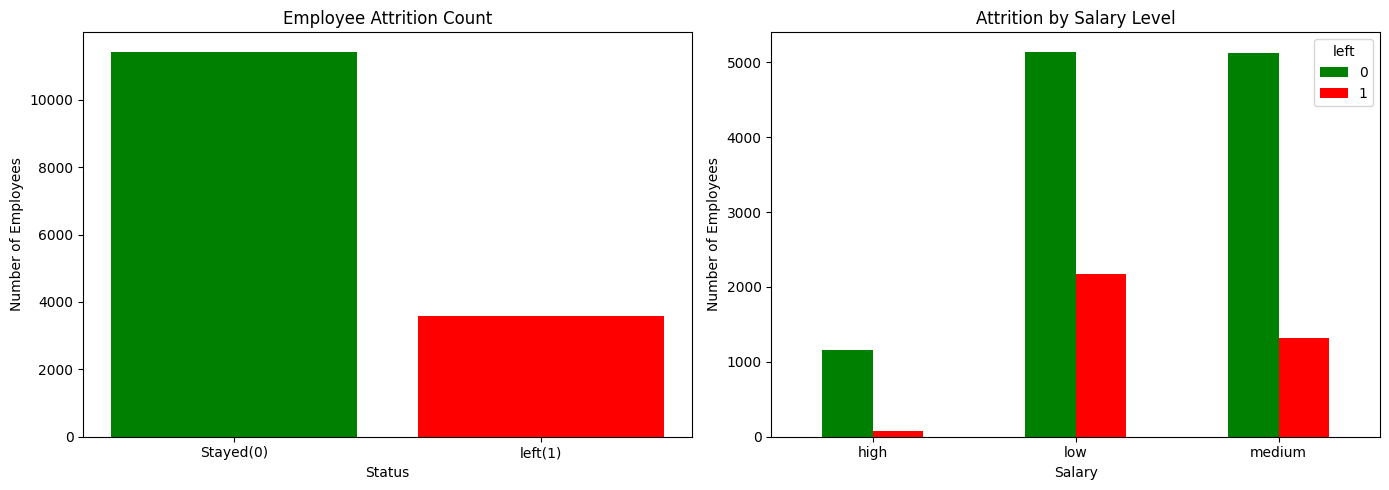

In [ ]:
# Exploratory Data Analysis
plt.figure(figsize=(14,5))

# 1.How many people left their jobs(Target analysis)
plt.subplot(1,2,1)
left_counts = df['left'].value_counts()
plt.bar(['Stayed(0)','left(1)'],left_counts.values,color=['green','red'])
plt.title('Employee Attrition Count')
plt.xlabel('Status')
plt.ylabel('Number of Employees')

# 2.Relation between salary and job turnover
plt.subplot(1,2,2)
salary_left = pd.crosstab(df['salary'],df['left'])
salary_left.plot(kind='bar',ax=plt.subplot(1,2,2),color=['green','red'])
plt.title("Attrition by Salary Level")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
# Feature processing

# 1.One-Hot Encoding
df_encoded = pd.get_dummies(df,columns=['salary'],drop_first = True)

# 2.seperate Time , Event and Features
time_col = 'time_spend_company'
event_col = 'left'
features = [c for c in df_encoded.columns if c not in [time_col,event_col,'empid']]

X = df_encoded[features]
E = df_encoded[event_col]
T = df_encoded[time_col]

Model: Logistic Regression
Accuracy: 0.7847 | Precision: 0.5838 | Recall: 0.2960 | F1-Score: 0.3929 | AUC: 0.7876
--------------------------------------------------------------------------------


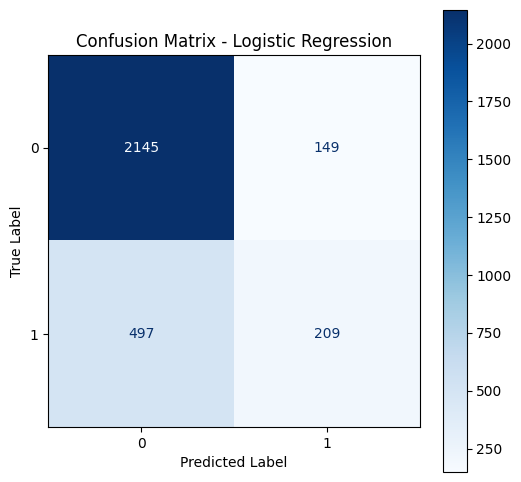

Model: Decision Tree
Accuracy: 0.9467 | Precision: 0.8760 | Recall: 0.9008 | F1-Score: 0.8883 | AUC: 0.9557
--------------------------------------------------------------------------------


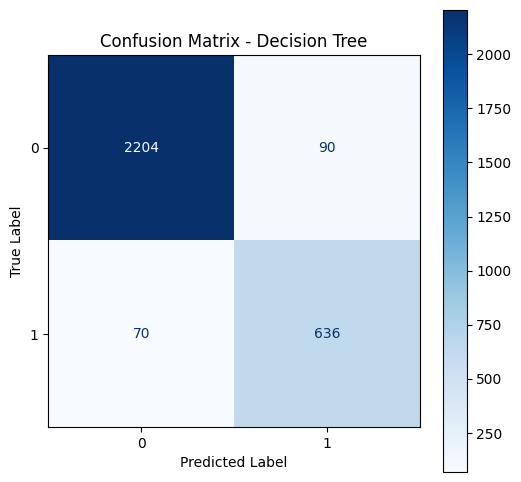

Model: K-Nearest Neighbors(k=5)
Accuracy: 0.9360 | Precision: 0.8589 | Recall: 0.8711 | F1-Score: 0.8650 | AUC: 0.9686
--------------------------------------------------------------------------------


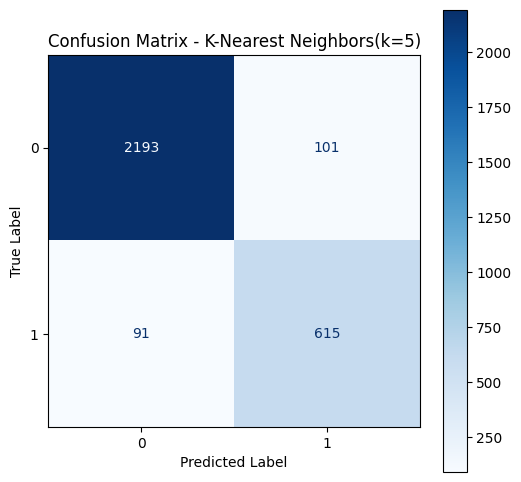

In [61]:
### Baseline Classification Models(Logistic Regression,Decision Tree,K Nearest Neighbors)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,ConfusionMatrixDisplay

# Perform train-test split for standard classification tasks
X_train, X_test, y_train, y_test = train_test_split(X, E, test_size=0.2, random_state=42)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Classification_Model = {
    'Logistic Regression':LogisticRegression(max_iter=1000,random_state=42),
    'Decision Tree':DecisionTreeClassifier(max_depth=5,random_state=42),
    'K-Nearest Neighbors(k=5)':KNeighborsClassifier(n_neighbors=5)
}

for name,model in Classification_Model.items():
  model.fit(X_train_scaled,y_train)
  preds = model.predict(X_test_scaled)
  probs = model.predict_proba(X_test_scaled)[:,1]
  accuracy = accuracy_score(y_test,preds)
  precision = precision_score(y_test,preds)
  recall = recall_score(y_test,preds)
  f1 = f1_score(y_test,preds)
  auc = roc_auc_score(y_test,probs)

  print(f"Model: {name}")
  print(f"Accuracy: {accuracy:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f} | F1-Score: {f1:.4f} | AUC: {auc:.4f}")
  print("-"*80)

  # Confusion Matrix Plot
  fig,ax = plt.subplots(figsize=(6,6))
  ConfusionMatrixDisplay.from_predictions(
      y_test,preds,ax=ax,cmap=plt.cm.Blues,colorbar=True
  )
  plt.title(f"Confusion Matrix - {name}")
  plt.xlabel("Predicted Label")
  plt.ylabel("True Label")
  plt.show()

In [ ]:
### Cross-Validation & Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV

# 1.Logistic Regression - 5-Fold CV & Hyperparameter Tuning
lr_param_grid ={
    'C':[0.01,0.1,1,10,100],
    'penalty':['l2'],
    'solver':['lbfgs']
}
lr_grid = GridSearchCV(
    LogisticRegression(max_iter=1000,random_state=42),
    param_grid=lr_param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)
lr_grid.fit(X_train_scaled,y_train)

print("Best Logistic Regression hyperparameters:",lr_grid.best_params_)
print("Best AUC Score for Logistic Regression:",lr_grid.best_score_)
print(
    "Best Logistic regression Test Accuracy:",
    round(lr_grid.best_estimator_.score(X_test_scaled,y_test),4)
)
print('-'*60)

# 2.Decision Tree
dt_param_grid = {
    'max_depth':[None,4,5,7,10],
    'min_samples_split':[2,5,10],
    'min_samples_leaf':[1,2,5]
}
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)
dt_grid.fit(X_train_scaled,y_train)

print("Best Decision Tree Hyperparameters:",dt_grid.best_params_)
print("Best AUC Score for Decision Tree:",dt_grid.best_score_)
print(
    "Best Decision Tree Test Accuracy:",
    round(dt_grid.best_estimator_.score(X_test_scaled,y_test),4)
)
print('-'*60)

# 3.KNN
knn_param_grid = {
    'n_neighbors':[3,5,7,9],
    'weights':['uniform','distance'],
}
knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid=knn_param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)
knn_grid.fit(X_train_scaled,y_train)

print("Best KNN Hyperparameters:",knn_grid.best_params_)
print("Best AUC Score for KNN:",knn_grid.best_score_)
print(
    "Best KNN Test Accuracy:",
    round(knn_grid.best_estimator_.score(X_test_scaled,y_test),4)
)
print('-'*60)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Best Logistic Regression hyperparameters: {'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}
Best AUC Score for Logistic Regression: 0.7958997665962734
Best Logistic regression Test Accuracy: 0.7847
------------------------------------------------------------
Best Decision Tree Hyperparameters: {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best AUC Score for Decision Tree: 0.9774895164746319
Best Decision Tree Test Accuracy: 0.9507
------------------------------------------------------------
Best KNN Hyperparameters: {'n_neighbors': 9, 'weights': 'distance'}
Best AUC Score for KNN: 0.978764926752363
Best KNN Test Accuracy: 0.9613
------------------------------------------------------------


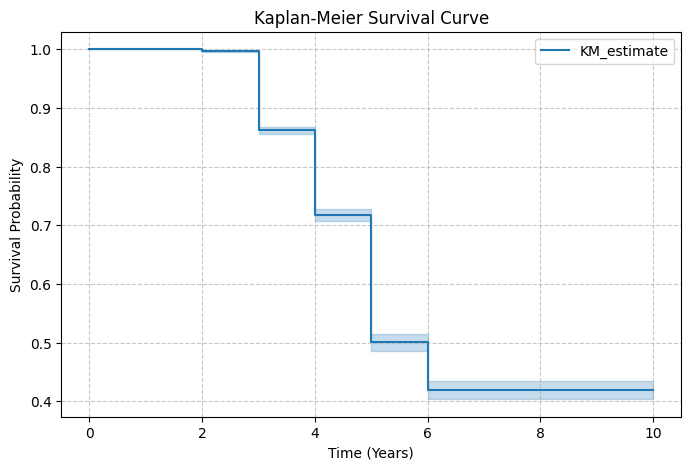

C-Index on Test Set: 0.8471


In [62]:
### Baseline Survival Models(Kaplan-Meier Curve & Cox Proportional Hazards)
from lifelines import CoxPHFitter, KaplanMeierFitter
from sksurv.metrics import concordance_index_censored

# 1.Kaplan-Meier Survival Curve
kmf = KaplanMeierFitter()
kmf.fit(durations=df_model[time_col], event_observed=df_model[event_col])

plt.figure(figsize=(8,5))
kmf.plot_survival_function()
plt.title("Kaplan-Meier Survival Curve")
plt.xlabel("Time (Years)")
plt.ylabel("Survival Probability")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# 2.Cox Proportional Hazards Model
df_cox_train = pd.DataFrame(X_train_scaled, columns=X.columns)
df_cox_train[time_col] = df_model.loc[X_train.index, time_col].values
df_cox_train[event_col] = df_model.loc[X_train.index, event_col].values

df_cox_test = pd.DataFrame(X_test_scaled, columns=X.columns)
df_cox_test[time_col] = df_model.loc[X_test.index, time_col].values
df_cox_test[event_col] = df_model.loc[X_test.index, event_col].values

cph = CoxPHFitter()
cph.fit(df_cox_train, duration_col=time_col, event_col=event_col)

# 3.C-index on Test Set
cox_risk = cph.predict_partial_hazard(df_cox_test).values.ravel()
cox_c_index = concordance_index_censored(df_cox_test[event_col].astype(bool), df_cox_test[time_col], cox_risk)[0]
print(f"C-Index on Test Set: {cox_c_index:.4f}")

Training Machine Learning Survival Model (Random Survival Forest)...
C-Index on Test Set:0.9611


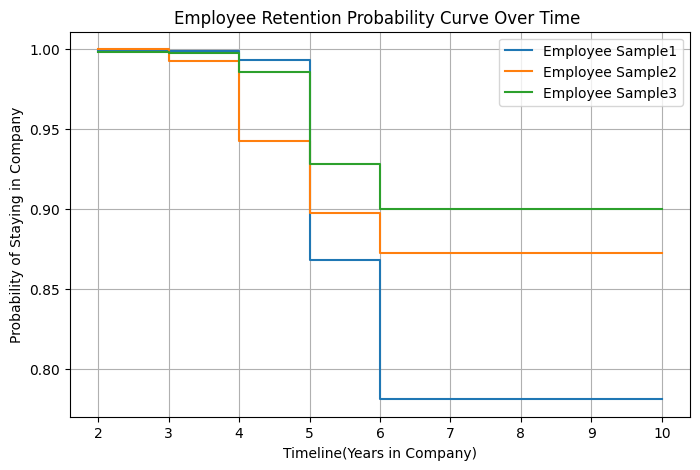

In [ ]:
# Random Survival Forest Model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sksurv.ensemble import RandomSurvivalForest

# 1. Feature and Target
cols_to_use = features + [time_col, event_col,'empid']
df_model = df_encoded[cols_to_use]

X = df_model.drop(columns=[time_col, event_col, 'empid'])
y_events = df_model[event_col].values
y_times = df_model[time_col]
y = np.array(list(zip(y_events, y_times)), dtype=[(event_col, '?'), (time_col, '<f8')])

# 2. Train-Test-Split
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2,random_state=42)

# 3. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Random Survival Forest Model Training
print("Training Machine Learning Survival Model (Random Survival Forest)...")
rsf = RandomSurvivalForest(n_estimators=150,
                           min_samples_split=10,
                           min_samples_leaf=5,
                           max_features='sqrt',
                           random_state=42,
                           n_jobs=-1)
rsf.fit(X_train_scaled, y_train)

# 5. Model Evaluation
c_index = rsf.score(X_test_scaled, y_test)
print(f"C-Index on Test Set:{c_index:.4f}")

# 6. Plotting Survival Curve of Some Employee from Test Set

surv_funcs = rsf.predict_survival_function(X_test_scaled[:3])

plt.figure(figsize=(8,5))
for i,fn in enumerate(surv_funcs):
  plt.step(fn.x, fn.y, where="post", label=f"Employee Sample{i+1}" )

plt.title("Employee Retention Probability Curve Over Time ")
plt.xlabel("Timeline(Years in Company)")
plt.ylabel("Probability of Staying in Company")
plt.legend()
plt.grid(True)
plt.show()

Evaluating Feature Importance...


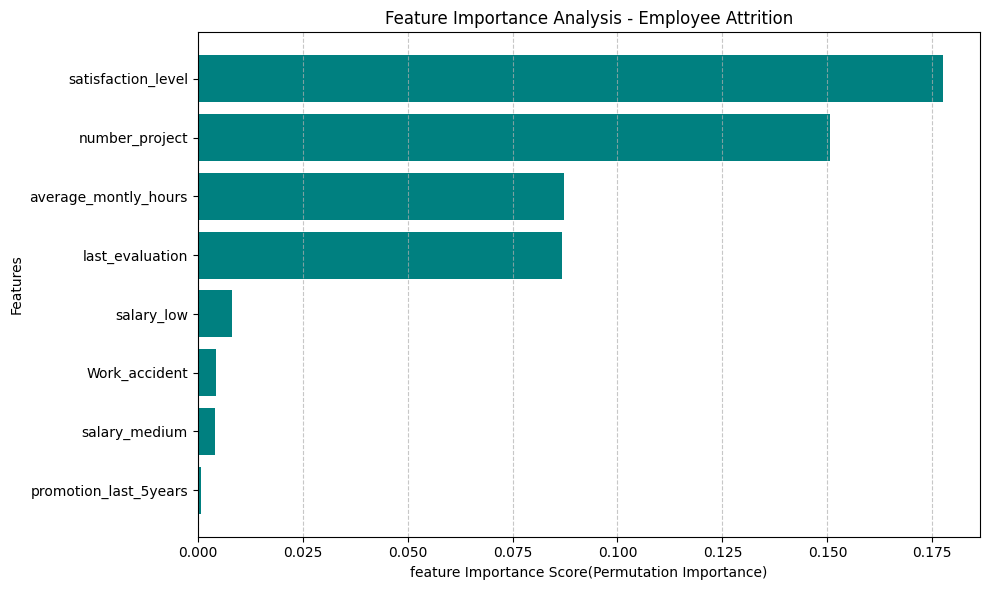


Feature Importance Scores:
                 Feature  Importance
0     satisfaction_level    0.177475
2         number_project    0.150584
3   average_montly_hours    0.087329
1        last_evaluation    0.086892
6             salary_low    0.008260
4          Work_accident    0.004482
7          salary_medium    0.004206
5  promotion_last_5years    0.000753


In [ ]:
### Feature Importance Analysis
from sklearn.inspection import permutation_importance

print("Evaluating Feature Importance...")
result = permutation_importance(
    rsf,X_test_scaled,y_test,n_repeats=10,random_state=42,n_jobs=-1
    )

feature_importance_df = pd.DataFrame({
    'Feature':X.columns,
    'Importance':result.importances_mean
}).sort_values('Importance',ascending=True)

plt.figure(figsize=(10,6))
plt.barh(feature_importance_df['Feature'],feature_importance_df['Importance'],color='teal')

plt.xlabel("feature Importance Score(Permutation Importance)")
plt.ylabel("Features")
plt.title("Feature Importance Analysis - Employee Attrition")
plt.grid(axis='x',linestyle='--',alpha=0.7)
plt.tight_layout()
plt.show()

print("\nFeature Importance Scores:")
print(feature_importance_df.sort_values(by='Importance',ascending=False))



Employee Risk Segmentation:
Risk_Category
High Risk(Need Attention)    1020
Medium Risk(Monitor)          990
Low Risk(safe)                990
Name: count, dtype: int64

Sample of Employee Risk Predictions(First 10):
   Employee_index  Risk_Score              Risk_Category
0               0    0.406372       Medium Risk(Monitor)
1               1    0.297667       Medium Risk(Monitor)
2               2    0.209099       Medium Risk(Monitor)
3               3    4.139474  High Risk(Need Attention)
4               4    0.204037       Medium Risk(Monitor)
5               5    0.707619  High Risk(Need Attention)
6               6    0.046677             Low Risk(safe)
7               7    0.388912       Medium Risk(Monitor)
8               8    0.062795             Low Risk(safe)
9               9    0.291172       Medium Risk(Monitor)


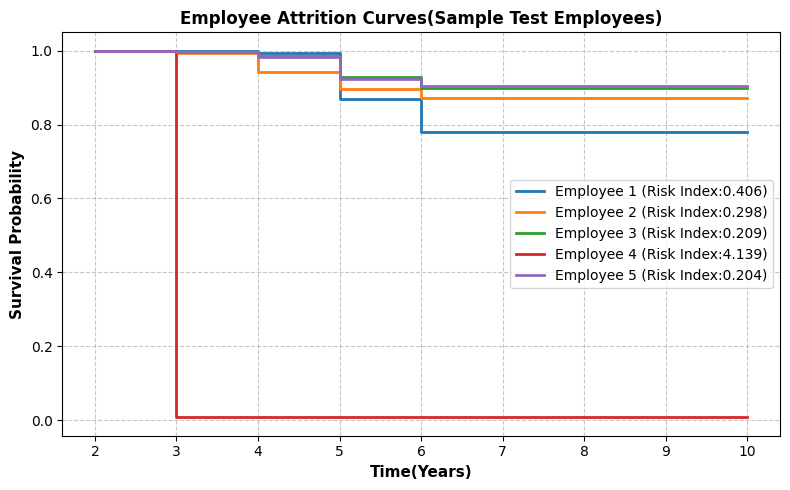

In [ ]:
### Employee Risk Segmentation
risk_scores = rsf.predict(X_test_scaled)

low_threshold = np.percentile(risk_scores,33)  # Using percentiles to divide scores into three groups
high_threshold = np.percentile(risk_scores,66) # The bottom 33 % is low risk,the middle 33% is moderate,and the top 33% is high risk

def classify_risk(score):
  if score <= low_threshold:
    return "Low Risk(safe)"
  elif score <= high_threshold:
    return "Medium Risk(Monitor)"
  else:
    return "High Risk(Need Attention)"

risk_categories = [classify_risk(score) for score in risk_scores]

segmented_df = pd.DataFrame({
    'Employee_index':range(len(risk_scores)),
    'Risk_Score':risk_scores,
    'Risk_Category':risk_categories
})

print("\nEmployee Risk Segmentation:")
print(segmented_df['Risk_Category'].value_counts())
print("\nSample of Employee Risk Predictions(First 10):")
print(segmented_df.head(10))

surv_funcs = rsf.predict_survival_function(X_test_scaled[:5])

plt.figure(figsize=(8,5))
for i,fn in enumerate(surv_funcs):
  plt.step(fn.x,
           fn.y,
           where="post",
           linewidth=2,
           label=f"Employee {i+1} (Risk Index:{risk_scores[i]:.3f})"
           )

plt.xlabel("Time(Years)",fontsize=11,fontweight="bold")
plt.ylabel("Survival Probability",fontsize=11,fontweight="bold")
plt.title(
    "Employee Attrition Curves(Sample Test Employees)",
    fontsize=12,
    fontweight="bold"
)
plt.grid(True,linestyle='--',alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
### Model Comparison with XGBoost Survival
import xgboost as xgb
from sksurv.metrics import concordance_index_censored

y_train_xgb = np.where(y_train[event_col], y_train[time_col], -y_train[time_col])
y_test_xgb = np.where(y_test[event_col], y_test[time_col], -y_test[time_col])

xgb_surv = xgb.XGBRegressor(objective='survival:cox',
                            eval_metric='cox-nloglik',
                            n_estimators=100,
                            learning_rate=0.1,
                            max_depth=3,
                            random_state=42
                            )
print("Training Machine Learning Survival Model (XGBoost)...")
xgb_surv.fit(X_train_scaled, y_train_xgb)

risk_scores_xgb = xgb_surv.predict(X_test_scaled)

xgb_c_index = concordance_index_censored(
    y_test[event_col], y_test[time_col], risk_scores_xgb
)[0]

print(f"Random Survival Forest C-Index;{c_index:4f}")
print(f"XGBoost Survival C-Index: {xgb_c_index:.4f}")

Training Machine Learning Survival Model (XGBoost)...
Random Survival Forest C-Index;0.961119
XGBoost Survival C-Index: 0.9618


In [63]:
### Advanced Survival Evaluation;Time-Dependent AUC & Integrated Brier Score
from sksurv.metrics import (
    brier_score,
    cumulative_dynamic_auc,
    integrated_brier_score
)

# Re-extract the structured survival target values based on matching indices of the train/test split
y_train_struct = y[X_train.index]
y_test_struct = y[X_test.index]

test_times = np.asarray([val[1] for val in y_test_struct], dtype=float)
max_t = np.max(test_times)
times = np.percentile(test_times, [25, 50, 75])
times = np.unique(times[times < max_t])

# Random Survival Forest - Time-dependent AUC & Integrated Brier Score
rsf_risk_scores = rsf.predict(X_test_scaled)
rsf_mean_auc = cumulative_dynamic_auc(y_train_struct, y_test_struct, rsf_risk_scores, times)

rsf_surv_funcs = rsf.predict_survival_function(X_test_scaled)
rsf_preds_surv = np.asarray([[fn(t) for t in times] for fn in rsf_surv_funcs])

rsf_brier = brier_score(y_train_struct, y_test_struct, rsf_preds_surv, times)
rsf_ibs = integrated_brier_score(y_train_struct, y_test_struct, rsf_preds_surv, times)

# XGBoost Survival - Time-dependent AUC (by risk scores)
xgb_risk_scores = xgb_surv.predict(X_test_scaled)
xgb_mean_auc = cumulative_dynamic_auc(y_train_struct, y_test_struct, xgb_risk_scores, times)

print(f'Random Survival Forest -> Mean Time-dependent AUC: {rsf_mean_auc[0].mean():.4f}')
print(f'Random Survival Forest -> Integrated Brier Score(IBS): {rsf_ibs:.4f}')
print('-'*60)
print(f'XGBoost -> Mean Time-dependent AUC: {xgb_mean_auc[0].mean():.4f}')

Random Survival Forest -> Mean Time-dependent AUC: 0.9610
Random Survival Forest -> Integrated Brier Score(IBS): 0.0258
------------------------------------------------------------
XGBoost -> Mean Time-dependent AUC: 0.9695
